# E04-DB — DBSCAN trên RFM + AOV + Diversity (cap P99 + lọc tương quan + log1p + Standard, không PCA)

Thí nghiệm **E04-DB** (người chạy: Nguyên) theo chiến lược model. So với E01, **chỉ bỏ PCA**: làm sạch → 5 feature → cap P99 (Frequency, Monetary, AOV, Diversity; giữ Recency) → lọc tương quan |Spearman| > 0,90 (trên feature đã cap, trước log) → `log1p` → StandardScaler → **DBSCAN trực tiếp trên không gian 5 chiều**. Đây là phép ablation: đo xem PCA 90% có ảnh hưởng đến cấu trúc mật độ mà DBSCAN nhìn thấy hay không. Bảng chiến lược yêu cầu đối chiếu E04 với E01 và A02.

Bước lọc tương quan ở E01 không loại biến nào (xem bên dưới), nên **E01 cùng tập feature và cùng cấu hình với D01** (cap P99, Standard, PCA 90%). D01-DB và E01-DB chưa có trong repo nên được dựng lại ngay trong notebook; A02-DB (RFM thô, không PCA) lấy từ nhãn của Thuận. Lưới `eps × min_samples` (72 cấu hình) và quy tắc chọn giữ nguyên như D02-DB, E02-DB của Thuận và D04-DB.

## Params

In [1]:
FEATURES = ["Recency", "Frequency", "Monetary", "AOV", "Diversity"]
CAP_FEATURES = ["Frequency", "Monetary", "AOV", "Diversity"]   # cap các biến này; Recency giữ nguyên
CAP_Q = 99                          # P99, giống D01 / D04
CORR_THR = 0.90                     # E04: ngưỡng lọc tương quan (E02 = 0,85; E03 = 0,95)
PRIORITY = ["Recency", "Frequency", "Monetary", "Diversity", "AOV"]   # khi một cặp vượt ngưỡng, bỏ biến đứng sau
PCA_VAR = 0.90                      # chỉ dùng cho cấu hình đối chiếu E01 (≡ D01); E04 không dùng PCA
MIN_SAMPLES_GRID = [4, 6, 8, 10, 15, 20]
EPS_GRID = [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5, 2.0]   # 12 giá trị, giống D02-DB / E02-DB / D04-DB
RANDOM_STATE = 42
MAX_NOISE = 0.05                    # điều kiện chọn: nhiễu tối đa 5% số khách
MIN_CLUSTERS = 2                    # điều kiện chọn: ít nhất 2 cụm (không tính nhiễu)

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

def find(rel):
    # Tự tìm file trong repo, không phụ thuộc nơi mở notebook
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01..D04), không sao chép thêm
DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

# AOV = avg_order_value, Diversity = n_stock_codes (số mã hàng khác nhau của khách)
df = pd.read_csv(DATA, dtype={"CustomerID": "string"}).rename(columns={"avg_order_value": "AOV", "n_stock_codes": "Diversity"})
X = df[FEATURES].astype(float)
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()   # log1p cần X >= 0
assert np.allclose(df["AOV"], df["Monetary"] / df["Frequency"], atol=0.01)              # AOV = Monetary / Frequency
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 5)


,Recency,Frequency,Monetary,AOV,Diversity
count,4327.00,4327.00,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95,372.40,61.49
std,99.98,7.64,8441.89,466.49,85.31
min,1.00,1.00,2.90,2.90,1.00
25%,18.00,1.00,301.52,175.47,16.00
50%,51.00,2.00,657.90,286.70,35.00
75%,143.00,5.00,1624.10,421.99,77.00
max,374.00,206.00,278748.02,14844.77,1784.00


**Nhận xét:** 4.327 khách, 5 feature, không thiếu giá trị, không có giá trị âm. Cùng tệp đặc trưng 4.327 khách với các thí nghiệm A–D.

## Winsorization P99 và lọc tương quan

Cap giống hệt D01 (P99 cho Frequency, Monetary, AOV, Diversity; Recency không cap; không xóa khách nào). Sau đó lọc tương quan Spearman trên feature **đã cap, trước log**: với mỗi cặp có |ρ| > ngưỡng, bỏ biến đứng sau theo thứ tự ưu tiên R, F, M, Diversity, AOV.

In [3]:
caps = X.quantile(CAP_Q / 100)
caps[[c for c in FEATURES if c not in CAP_FEATURES]] = np.inf        # Recency giữ nguyên
capped = X.gt(caps, axis=1)
X_cap = X.clip(upper=caps, axis=1)
cap_report = pd.DataFrame({
    "cap": caps.replace(np.inf, np.nan).round(2),
    "customers_capped": capped.sum(),
    "customers_capped_pct": (100 * capped.mean()).round(2),
    "value_capped_pct": (100 * (X - X_cap).sum() / X.sum()).round(2),
})
n_capped = int(capped.any(axis=1).sum())
print(f"Khách bị cap ở ít nhất 1 biến: {n_capped} ({100 * n_capped / len(X):.2f}%) | không xóa khách nào")

def correlation_filter(Xc, thr):
    rho = Xc.corr(method="spearman").abs()
    dropped = []
    pairs = sorted(((rho.loc[a, b], a, b) for i, a in enumerate(Xc.columns) for b in Xc.columns[i + 1:]), reverse=True)
    for r, a, b in pairs:
        if r <= thr:
            break
        if a in dropped or b in dropped:
            continue
        dropped.append(max((a, b), key=PRIORITY.index))
    return dropped

rho = X_cap.corr(method="spearman")
off = rho.abs().where(~np.eye(len(rho), dtype=bool))
max_rho = float(off.max().max())
dropped = correlation_filter(X_cap, CORR_THR)
print(f"|Spearman| lớn nhất giữa hai biến: {max_rho:.4f}")
print("Biến bị loại ở ngưỡng 0,90:", dropped if dropped else "không có")
print("Biến bị loại ở các ngưỡng 0,85 / 0,95:", correlation_filter(X_cap, 0.85) or "không có", "/", correlation_filter(X_cap, 0.95) or "không có")
FEATURES_USED = [f for f in FEATURES if f not in dropped]
print("Feature đưa vào mô hình:", FEATURES_USED)
print(); print(cap_report.to_string()); print(); print(rho.round(3).to_string())

Khách bị cap ở ít nhất 1 biến: 116 (2.68%) | không xóa khách nào
|Spearman| lớn nhất giữa hai biến: 0.8094
Biến bị loại ở ngưỡng 0,90: không có
Biến bị loại ở các ngưỡng 0,85 / 0,95: không có / không có
Feature đưa vào mô hình: ['Recency', 'Frequency', 'Monetary', 'AOV', 'Diversity']

                cap  customers_capped  customers_capped_pct  value_capped_pct
Recency         NaN                 0                  0.00              0.00
Frequency     30.00                42                  0.97              6.12
Monetary   17279.06                44                  1.02             21.62
AOV         1894.54                44                  1.02              4.45
Diversity    353.74                44                  1.02              3.50

           Recency  Frequency  Monetary    AOV  Diversity
Recency      1.000     -0.564    -0.485 -0.132     -0.456
Frequency   -0.564      1.000     0.809  0.162      0.655
Monetary    -0.485      0.809     1.000  0.679      0.732
AOV         -

**Nhận xét:** Ngưỡng P99 là Frequency 30, Monetary 17.279, AOV 1.895, Diversity 354; 116 khách (2,68%) bị cap, cắt 21,62% tổng Monetary (giống D01). **|Spearman| lớn nhất giữa hai biến chỉ 0,8094** (Frequency với Monetary), thấp hơn cả ba ngưỡng 0,85, 0,90 và 0,95, nên **không biến nào bị loại**. Vì vậy E04-DB dùng đủ 5 feature và E01, E02, E03 cùng tập feature với D01 (đúng ghi chú của bảng chiến lược ở E03: "Nếu không bỏ biến: ghi tương đương D01").

## Chuẩn hóa, không PCA

E04 đưa thẳng 5 chiều đã cap, log1p và Standard vào DBSCAN. Để so, dựng thêm không gian của E01 (≡ D01): cùng các bước rồi PCA giữ 90% phương sai.

In [4]:
def make_prep(caps_values, n_components=None):
    steps = [("cap", FunctionTransformer(np.clip, kw_args={"a_min": None, "a_max": caps_values})),
             ("log1p", FunctionTransformer(np.log1p)),
             ("scaler", StandardScaler())]
    if n_components is not None:
        steps.append(("pca", PCA(n_components=n_components, svd_solver="full", random_state=RANDOM_STATE)))
    return Pipeline(steps)

caps_values = caps[FEATURES_USED].to_numpy()
X_in = X[FEATURES_USED].values
prep = make_prep(caps_values).fit(X_in)
Z = prep.transform(X_in)                                   # E04: 5 chiều, không PCA

pca_full = PCA(svd_solver="full").fit(Z)
ev = pca_full.explained_variance_ratio_
cum = np.cumsum(ev)
n_pc = int(np.searchsorted(cum, PCA_VAR) + 1)
Z_e01 = PCA(n_components=n_pc, svd_solver="full", random_state=RANDOM_STATE).fit_transform(Z)   # E01 ≡ D01: PCA 90%

print("Kích thước đầu vào E04:", Z.shape, "| E01 (PCA 90%):", Z_e01.shape)
print("Phương sai từng PC (chỉ để tham khảo):", ev.round(4))
print("Phương sai tích lũy:", cum.round(4), f"| E01 giữ {n_pc}/{len(FEATURES_USED)} PC ({cum[n_pc-1]:.2%})")
print("\nHệ số (loading) của từng PC trên feature đã chuẩn hóa:")
print(pd.DataFrame(pca_full.components_, columns=FEATURES_USED, index=[f"PC{i+1}" for i in range(len(ev))]).round(3).to_string())

Kích thước đầu vào E04: (4327, 5) | E01 (PCA 90%): (4327, 3)
Phương sai từng PC (chỉ để tham khảo): [0.6237 0.2025 0.0979 0.0747 0.0012]
Phương sai tích lũy: [0.6237 0.8262 0.9241 0.9988 1.    ] | E01 giữ 3/5 PC (92.41%)

Hệ số (loading) của từng PC trên feature đã chuẩn hóa:
     Recency  Frequency  Monetary    AOV  Diversity
PC1   -0.375      0.475     0.542  0.343      0.472
PC2    0.524     -0.366     0.178  0.748      0.037
PC3    0.755      0.417     0.087 -0.362      0.342
PC4   -0.124     -0.445    -0.346 -0.089      0.812
PC5    0.001     -0.518     0.740 -0.430     -0.016


**Nhận xét:** E04 giữ nguyên 5 chiều; E01 (PCA 90%) giữ 3 PC (92,41% phương sai) và bỏ 2 chiều chứa 7,59% phương sai còn lại. PC4 (7,47%) chủ yếu là chiều Diversity (hệ số 0,81), còn PC5 (0,12%) gần như là hệ thức Monetary ≈ Frequency × AOV (hệ số Monetary 0,74, Frequency −0,52, AOV −0,43), tức phần thừa vì AOV = Monetary / Frequency. Vì DBSCAN dùng khoảng cách Euclid, hai chiều bị bỏ là phần thông tin mà ablation này kiểm tra.

## Chọn eps bằng đồ thị k-distance và kiểm tra thang eps

Với mỗi `min_samples`, tính khoảng cách từ mỗi khách đến láng giềng thứ `min_samples` (tính cả chính nó), sắp xếp tăng dần. Không gian 5 chiều có khoảng cách lớn hơn không gian 3 chiều của E01, nên đo xem lưới eps gốc có còn phủ vùng cần quét hay không.

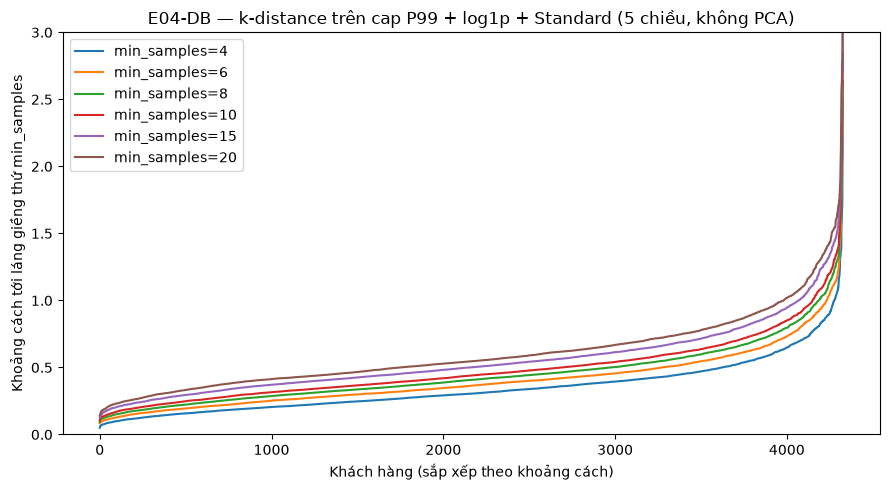

Hệ số thang (5 chiều / 3 chiều PCA) = trung vị tỷ số P99 của k-distance = 1.392

k-distance E04 (5 chiều):
        4      6      8      10     15     20
P50  0.305  0.363  0.407  0.440  0.501  0.546
P90  0.589  0.668  0.734  0.783  0.878  0.942
P95  0.722  0.837  0.897  0.948  1.050  1.132
P99  1.019  1.138  1.253  1.324  1.458  1.556

k-distance E01 (PCA 90%, 3 chiều):
        4      6      8      10     15     20
P50  0.195  0.238  0.266  0.291  0.338  0.376
P90  0.372  0.441  0.489  0.526  0.609  0.671
P95  0.458  0.541  0.601  0.657  0.753  0.836
P99  0.697  0.804  0.868  0.968  1.143  1.235


In [5]:
def kdist(Zs):
    d = {ms: np.sort(NearestNeighbors(n_neighbors=ms).fit(Zs).kneighbors(Zs)[0][:, -1]) for ms in MIN_SAMPLES_GRID}
    q = pd.DataFrame({ms: np.quantile(v, [0.5, 0.9, 0.95, 0.99]) for ms, v in d.items()}, index=["P50", "P90", "P95", "P99"])
    return d, q

kd, q5 = kdist(Z)
_, q3 = kdist(Z_e01)

fig, ax = plt.subplots(figsize=(9, 5))
for ms, d in kd.items():
    ax.plot(d, label=f"min_samples={ms}")
ax.set_ylim(0, 3)
ax.set_xlabel("Khách hàng (sắp xếp theo khoảng cách)")
ax.set_ylabel("Khoảng cách tới láng giềng thứ min_samples")
ax.set_title("E04-DB — k-distance trên cap P99 + log1p + Standard (5 chiều, không PCA)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "k_distance.png", dpi=150); plt.show()

scale = float(np.median([q5.loc["P99", ms] / q3.loc["P99", ms] for ms in MIN_SAMPLES_GRID]))
print(f"Hệ số thang (5 chiều / 3 chiều PCA) = trung vị tỷ số P99 của k-distance = {scale:.3f}")
print("\nk-distance E04 (5 chiều):"); print(q5.round(3).to_string())
print("\nk-distance E01 (PCA 90%, 3 chiều):"); print(q3.round(3).to_string())

**Nhận xét:** Khoảng cách trong không gian 5 chiều lớn hơn không gian PCA 3 chiều khoảng 39% (hệ số ≈ 1,39; P99 của k-distance từ 1,02 đến 1,56 so với 0,70 đến 1,24), nhưng **lưới eps gốc (0,05–2,0) vẫn phủ từ P50 (0,31–0,55) tới trên P99**. Đồ thị k-distance không có khuỷu rõ: đường tăng chậm rồi chỉ dốc lên trong khoảng 5% khách cuối (từ P95, k-distance 0,72 đến 1,13), nên eps không chọn được bằng khuỷu mà phải quét lưới. E04 dùng nguyên lưới gốc để giữ nguyên giao thức; phép quy đổi eps theo hệ số 1,39 được chạy bên dưới như kiểm tra độ nhạy.

## Quét lưới eps × min_samples (E04)

Silhouette và DBI chỉ tính trên khách **không bị gán nhiễu** và chỉ khi có ≥ 2 cụm.

In [6]:
def run_dbscan(Zs, eps, ms):
    labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(Zs)
    mask = labels != -1
    sizes = pd.Series(labels[mask]).value_counts()
    k = len(sizes)
    row = {"min_samples": ms, "eps": eps, "n_clusters": k,
           "noise_pct": round(100 * (~mask).mean(), 2),
           "largest_pct": round(100 * sizes.iloc[0] / len(Zs), 2) if k else np.nan,
           "smallest": int(sizes.iloc[-1]) if k else 0,
           "silhouette": np.nan, "dbi": np.nan}
    if k >= 2:
        row["silhouette"] = silhouette_score(Zs[mask], labels[mask])
        row["dbi"] = davies_bouldin_score(Zs[mask], labels[mask])
    return row, labels

def run_grid(Zs, eps_grid):
    pairs = [(e, m) for m in MIN_SAMPLES_GRID for e in eps_grid]
    out = [run_dbscan(Zs, e, m) for e, m in pairs]
    return pd.DataFrame([r for r, _ in out]), {p: l for p, (_, l) in zip(pairs, out)}

def select(g):
    # ≥ 2 cụm, nhiễu ≤ 5%, Silhouette cao nhất; hòa thì lấy nhiễu thấp hơn (giống D02-DB của Thuận)
    valid = g[(g["n_clusters"] >= MIN_CLUSTERS) & (g["noise_pct"] <= MAX_NOISE * 100)]
    if valid.empty:
        return None, valid
    return valid.sort_values(["silhouette", "noise_pct"], ascending=[False, True]).iloc[0], valid

grid, lab_e04 = run_grid(Z, EPS_GRID)
print("Số cấu hình đã chạy:", len(grid))
print("Số cấu hình có >= 2 cụm:", int((grid["n_clusters"] >= 2).sum()), "| chỉ 1 cụm:", int((grid["n_clusters"] == 1).sum()))
multi_ = grid[grid["n_clusters"] >= 2]
print("Trong các cấu hình có >= 2 cụm, số cấu hình có nhiễu <= 5% / <= 10% / <= 20% / > 50%:",
      int((multi_["noise_pct"] <= 5).sum()), "/", int((multi_["noise_pct"] <= 10).sum()), "/",
      int((multi_["noise_pct"] <= 20).sum()), "/", int((multi_["noise_pct"] > 50).sum()))
grid[grid["n_clusters"] >= 2].sort_values("silhouette", ascending=False).head(8).round(4)

Số cấu hình đã chạy: 72
Số cấu hình có >= 2 cụm: 42 | chỉ 1 cụm: 21
Trong các cấu hình có >= 2 cụm, số cấu hình có nhiễu <= 5% / <= 10% / <= 20% / > 50%: 2 / 5 / 9 / 25


,min_samples,eps,n_clusters,noise_pct,largest_pct,smallest,silhouette,dbi
63,20,0.20,2,97.02,2.15,36,0.7614,0.3100
26,8,0.15,7,95.24,2.01,8,0.4987,0.5540
1,4,0.10,25,95.79,0.86,4,0.4933,0.5479
51,15,0.20,5,94.38,2.63,23,0.4799,0.6123
38,10,0.15,6,96.88,1.22,8,0.4700,0.6880
13,6,0.10,5,98.82,0.62,5,0.4144,0.6740
14,6,0.15,20,91.47,2.63,6,0.4022,0.5524
64,20,0.25,2,91.93,6.75,57,0.3697,0.7550


**Nhận xét:** 42/72 cấu hình có ≥ 2 cụm (E01 ≡ D01: 35/72). Nhưng 25 trong 42 cấu hình đó có hơn 50% khách bị gán nhiễu (ví dụ min_samples = 20, eps = 0,20: 97,0% nhiễu, Silhouette 0,7614 chỉ vì có vài cụm rất nhỏ và đặc), nên Silhouette cao ở đây không có giá trị phân khúc. Chỉ 2 cấu hình có nhiễu ≤ 5%, 5 cấu hình ≤ 10% và 9 cấu hình ≤ 20%.

## Chọn cấu hình

Cùng quy tắc của nhánh D (đặt trước khi xem kết quả): ≥ 2 cụm, nhiễu ≤ 5% số khách, **Silhouette cao nhất**, hòa thì lấy nhiễu thấp hơn.

In [7]:
best, valid = select(grid)
print(f"Số cấu hình đạt điều kiện (>= 2 cụm, nhiễu <= 5%): {len(valid)}")
print("Cấu hình được chọn:")
print(best.round(4).to_string())
print()
valid.round(4)

Số cấu hình đạt điều kiện (>= 2 cụm, nhiễu <= 5%): 2
Cấu hình được chọn:
min_samples       6.0000
eps               0.7000
n_clusters        2.0000
noise_pct         4.7400
largest_pct      61.2000
smallest       1474.0000
silhouette        0.2527
dbi               1.3180



,min_samples,eps,n_clusters,noise_pct,largest_pct,smallest,silhouette,dbi
8,4,0.7,5,3.47,96.09,4,-0.0021,0.7021
20,6,0.7,2,4.74,61.20,1474,0.2527,1.3180


**Nhận xét:** Chỉ **2 cấu hình** đạt điều kiện. Cấu hình được chọn là `min_samples = 6`, `eps = 0,7`: **2 cụm lớn** (2.648 và 1.474 khách), nhiễu 4,74% (205 khách), Silhouette 0,2527, DBI 1,3180. Cụm lớn nhất chiếm 61,2% khách (so với 14 thí nghiệm DBSCAN khác trong repo ở mục đối chiếu bên dưới). Cấu hình còn lại (`min_samples = 4`, `eps = 0,7`: 5 cụm, nhiễu 3,47%, cụm lớn nhất 96,1%) có Silhouette âm (−0,0021). Lưu ý nhiễu 4,74% sát giới hạn 5%.

## Hồ sơ cụm

Nhãn `-1` là nhiễu. Mô tả bằng trung vị **trên thang gốc, trước khi cap**. Cột `Monetary_share_pct` là tỷ trọng tổng Monetary gốc của nhóm.

In [8]:
labels = lab_e04[(float(best["eps"]), int(best["min_samples"]))]
def profile(lab):
    p = X.assign(cluster=lab).groupby("cluster").agg(
        customers=("Monetary", "size"), Recency=("Recency", "median"), Frequency=("Frequency", "median"),
        Monetary=("Monetary", "median"), AOV=("AOV", "median"), Diversity=("Diversity", "median"), Monetary_sum=("Monetary", "sum"))
    p["customer_share_pct"] = (100 * p["customers"] / len(X)).round(2)
    p["Monetary_share_pct"] = (100 * p["Monetary_sum"] / p["Monetary_sum"].sum()).round(2)
    return p.drop(columns="Monetary_sum")

prof = profile(labels)
prof.round(1)

,customers,Recency,Frequency,Monetary,AOV,Diversity,customer_share_pct,Monetary_share_pct
cluster,,,,,,,,
-1,205,22.0,6.0,3152.7,635.7,18.0,4.7,32.8
0,2648,31.0,4.0,1092.5,294.6,57.5,61.2,61.4
1,1474,134.0,1.0,247.8,247.8,16.0,34.1,5.8


**Nhận xét** (tên nhóm chỉ là cách gọi gợi ý từ trung vị):
- **Cụm 0 (2.648 khách, 61,2%)**: Recency 31, Frequency 4, Monetary ≈ 1.093, AOV ≈ 295, Diversity 57,5 → **nhóm hoạt động: mua gần đây, khá thường xuyên, nhiều chủng loại**; chiếm 61,4% Monetary.
- **Cụm 1 (1.474 khách, 34,1%)**: Recency 134, Frequency 1, Monetary = AOV ≈ 248, Diversity 16 → **nhóm mua một lần, đã lâu**; chỉ 5,8% Monetary.
- **205 khách nhiễu (4,7%)**: Recency 22, Frequency 6, Monetary ≈ 3.153, AOV ≈ 636, Diversity 18 → theo trung vị là **khách giá trị cao nhưng Diversity thấp hơn cụm 0 (18 so với 57,5), không đủ gần nhau để thành cụm**; chiếm 32,8% Monetary.

Cách chia "hoạt động / mua một lần, đã lâu" cũng xuất hiện ở K-Means của Thuận trên cùng không gian (E04-KM, xem mục đối chiếu); ở DBSCAN, khách giá trị cao không tách thành cụm nhỏ mà bị gán nhiễu.

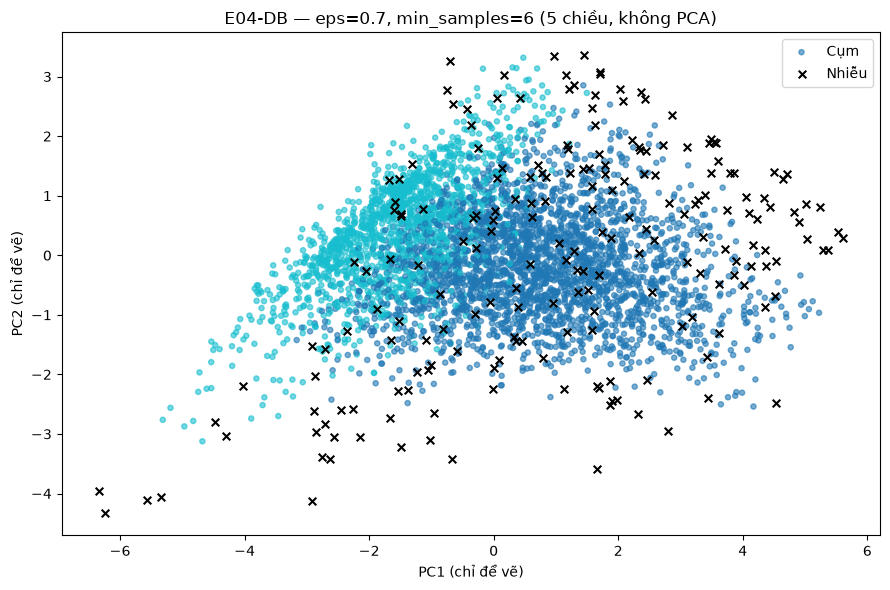

In [9]:
# Hình chiếu lên PC1-PC2 chỉ để VẼ (mô hình dùng đủ 5 chiều)
coords = PCA(n_components=2, svd_solver="full", random_state=RANDOM_STATE).fit_transform(Z)
fig, ax = plt.subplots(figsize=(9, 6))
noise = labels == -1
ax.scatter(coords[~noise, 0], coords[~noise, 1], c=labels[~noise], cmap="tab10", s=14, alpha=0.6, label="Cụm")
ax.scatter(coords[noise, 0], coords[noise, 1], c="black", marker="x", s=30, label="Nhiễu")
ax.set_xlabel("PC1 (chỉ để vẽ)"); ax.set_ylabel("PC2 (chỉ để vẽ)")
ax.set_title(f"E04-DB — eps={best['eps']}, min_samples={int(best['min_samples'])} (5 chiều, không PCA)")
ax.legend(); plt.tight_layout(); plt.savefig(FIG / "dbscan_clusters_pca.png", dpi=150); plt.show()

**Nhận xét:** Trên mặt phẳng PC1-PC2 hai cụm tách nhau chủ yếu theo PC1 (cụm mua một lần ở bên trái, cụm hoạt động ở giữa và bên phải) nhưng chồng lấn nhiều ở vùng giữa, vì hình 2 chiều chỉ giữ 82,62% phương sai và bỏ 3 chiều còn lại. Điểm nhiễu tập trung ở đuôi bên phải (PC1 lớn, tức giá trị cao) và rìa dưới; một số nằm giữa vùng đặc vì chúng bị tách ở các chiều không vẽ. Hình chiếu chỉ minh họa; mô hình chạy trên đủ 5 chiều.

## Chẩn đoán: vì sao bỏ PCA lại đổi kết quả?

Ba kiểm tra: (a) PCA giữ đủ 5/5 thành phần chỉ xoay trục, nên DBSCAN (khoảng cách Euclid) phải cho kết quả giống hệt không PCA; (b) giữ 3, 4, 5 thành phần để thấy chiều nào làm khác biệt; (c) quét eps mịn hơn lưới gốc ở min_samples = 6 để xem độ rộng của cấu trúc hai nhóm (chỉ chẩn đoán, không dùng để chọn cấu hình).

In [10]:
# (a), (b): PCA giữ n thành phần
rows, labs_n = [], {}
for nn in (3, 4, 5):
    Zn = PCA(n_components=nn, svd_solver="full", random_state=RANDOM_STATE).fit_transform(Z)
    gn, Ln = run_grid(Zn, EPS_GRID); bn, vn = select(gn)
    labs_n[nn] = Zn
    if bn is None:
        rows.append({"Số PC": nn, "Phương sai giữ": f"{cum[nn-1]:.2%}", "≥ 2 cụm": int((gn.n_clusters >= 2).sum()), "Đạt điều kiện": 0}); continue
    ln = Ln[(float(bn["eps"]), int(bn["min_samples"]))]
    rows.append({"Số PC": nn, "Phương sai giữ": f"{cum[nn-1]:.2%}", "≥ 2 cụm": int((gn.n_clusters >= 2).sum()), "Đạt điều kiện": len(vn),
                 "Chọn (min_samples, eps)": f"({int(bn['min_samples'])}, {bn['eps']})", "Số cụm": int(bn["n_clusters"]),
                 "Nhiễu (%)": bn["noise_pct"], "Silhouette": round(float(bn["silhouette"]), 4),
                 "ARI so với E04": round(adjusted_rand_score(labels, ln), 4),
                 "Số ô lưới giống hệt E04": sum(adjusted_rand_score(lab_e04[k], Ln[k]) == 1.0 for k in lab_e04)})
dim_test = pd.DataFrame(rows)
print(dim_test.to_string(index=False))

# (c): quét eps mịn, min_samples = 6
FINE = [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.9, 1.0]
fine = []
for nn, name in ((5, "5 chiều (E04)"), (4, "PCA 4 PC"), (3, "PCA 3 PC (E01)")):
    for e in FINE:
        r, _ = run_dbscan(labs_n[nn], e, 6)
        fine.append({"Không gian": name, "eps": e, "Số cụm": r["n_clusters"], "Nhiễu (%)": r["noise_pct"],
                     "Cụm lớn nhất (%)": r["largest_pct"], "Cụm nhỏ nhất": r["smallest"],
                     "Silhouette": round(float(r["silhouette"]), 4) if r["n_clusters"] >= 2 else np.nan})
fine = pd.DataFrame(fine)
print(); print(fine.pivot_table(index="eps", columns="Không gian", values=["Số cụm", "Nhiễu (%)", "Cụm lớn nhất (%)"], aggfunc="first").to_string())
print("\nÔ lưới gốc ở eps = 0,7 qua các min_samples (E04):")
print(grid[grid["eps"] == 0.7][["min_samples", "n_clusters", "noise_pct", "largest_pct", "smallest", "silhouette"]].round(4).to_string(index=False))

 Số PC Phương sai giữ  ≥ 2 cụm  Đạt điều kiện Chọn (min_samples, eps)  Số cụm  Nhiễu (%)  Silhouette  ARI so với E04  Số ô lưới giống hệt E04
     3         92.41%       35              3                (6, 0.5)       3       3.42      0.1351          0.0805                       11
     4         99.88%       41              1                (4, 0.7)       7       3.12     -0.0096          0.1374                       51
     5        100.00%       42              2                (6, 0.7)       2       4.74      0.2527          1.0000                       72



           Cụm lớn nhất (%)                             Nhiễu (%)                                Số cụm                        
Không gian    5 chiều (E04) PCA 3 PC (E01) PCA 4 PC 5 chiều (E04) PCA 3 PC (E01) PCA 4 PC 5 chiều (E04) PCA 3 PC (E01) PCA 4 PC
eps                                                                                                                            
0.50                  35.52          96.42    35.52         14.58           3.42    14.44            10              3       10
0.55                  56.41          98.13    56.46         10.72           1.87    10.65             4              1        4
0.60                  59.30          98.52    59.35          7.28           1.48     7.21             2              1        2
0.65                  60.55          99.01    60.62          5.62           0.99     5.55             2              1        2
0.70                  61.20          99.10    95.38          4.74           0.90     4.62             2

**Nhận xét:**
- **(a) PCA 5/5 trùng hoàn toàn không PCA:** ARI = 1,0 và 72/72 ô lưới giống hệt, đúng như lý thuyết (giữ đủ thành phần chỉ xoay trục).
- **(b) Mất chiều thì mất cấu trúc:** giữ 3 PC (E01 ≡ D01) không có eps nào chia được khối chính (eps 0,50: 3 cụm 4.172 / 4 / 3 khách; từ 0,55 trở lên chỉ 1 cụm; ARI 0,0805 so với E04). Giữ 4 PC (99,88% phương sai, chỉ bỏ PC5 gần thừa) thì cấu trúc hai nhóm còn, nhưng chỉ ở eps 0,60–0,65 với nhiễu 5,5–7,2%, nên quy tắc nhiễu ≤ 5% loại nó và chọn cấu hình khác (7 cụm, Silhouette −0,0096, ARI 0,1374). Vậy phần thông tin ở PC4 (chủ yếu là Diversity) là nghi vấn chính; đây là suy luận từ ba mức số PC, chưa kiểm bằng cách bỏ riêng Diversity.
- **(c) Cấu trúc hai nhóm có thật nhưng hẹp:** ở min_samples = 6, trong không gian 5 chiều hai cụm lớn xuất hiện ở eps 0,60–0,70 (nhiễu từ 7,28% xuống 4,74%) rồi ở eps 0,75 có 4 cụm (cụm lớn nhất 62,0%) và từ eps 0,80 cụm lớn nhất đã là 97,1% (hai cụm lớn nhập làm một). Với PCA 4 PC cửa sổ chỉ còn 0,60–0,65 (nhiễu 7,2–5,5%, vượt giới hạn 5%); với PCA 3 PC không có cửa sổ nào (chỉ một cụm từ eps 0,55 trở lên). Lưới gốc chỉ có một điểm (eps = 0,7) rơi vào cửa sổ và vừa đủ qua điều kiện nhiễu ≤ 5%.
- **Cấu trúc ổn định qua min_samples:** ở eps = 0,7, mọi min_samples từ 6 đến 20 đều cho đúng 2 cụm (cụm lớn nhất 56,55–61,2%, nhiễu 4,74–11,44%); min_samples nhỏ hơn làm cụm vỡ ra.

## Đối chiếu E01 (≡ D01), A02-DB và kiểm tra độ nhạy thang eps

Ba việc: (1) dựng lại E01-DB ≡ D01-DB (cap P99, Standard, PCA 90%, cùng lưới và quy tắc), đối chiếu E02-DB của Thuận (cùng tập feature); (2) so với A02-DB (RFM thô, không PCA; nhãn của Thuận) theo yêu cầu của bảng chiến lược; (3) chạy lại E04 với lưới eps nhân hệ số thang. ARI đo mức trùng nhóm (nhãn nhiễu −1 được tính như một nhóm), 1,0 là giống hệt.

In [11]:
# (1) E01 ≡ D01 dựng lại, đối chiếu E02-DB của Thuận
grid_e01, lab_e01 = run_grid(Z_e01, EPS_GRID)
best_e01, valid_e01 = select(grid_e01)
labels_e01 = lab_e01[(float(best_e01["eps"]), int(best_e01["min_samples"]))]
e02 = json.load(open(find("notebooks/03_clustering_eval/19-11-2026-thuan-dbscan-e02/data/dbscan_e02_params.json"), encoding="utf8"))
same_e02 = (e02["eps"] == float(best_e01["eps"]) and e02["min_samples"] == int(best_e01["min_samples"])
            and e02["n_clusters"] == int(best_e01["n_clusters"]) and abs(e02["silhouette_non_noise"] - best_e01["silhouette"]) < 1e-4)
print(f"E01-DB (≡ D01) dựng lại: eps={best_e01['eps']}, min_samples={int(best_e01['min_samples'])}, {int(best_e01['n_clusters'])} cụm, "
      f"nhiễu {best_e01['noise_pct']}%, Silhouette={best_e01['silhouette']:.4f}")
print(f"E02-DB của Thuận      : eps={e02['eps']}, min_samples={e02['min_samples']}, {e02['n_clusters']} cụm, nhiễu {e02['noise_pct']}%, "
      f"Silhouette={e02['silhouette_non_noise']:.4f} | trùng hoàn toàn: {same_e02}")

# (2) A02-DB (Thuận): RFM thô, Standard, không PCA
def load_labels(rel):
    t = pd.read_csv(find(rel), dtype={"CustomerID": "string"})
    return df[["CustomerID"]].merge(t, on="CustomerID", how="left")[t.columns[1]].to_numpy()
labels_a02 = load_labels("notebooks/03_clustering_eval/17-11-2026-thuan-dbscan-a02/data/dbscan_a02_labels.csv")
a02_sizes = {int(k): int(v) for k, v in zip(*np.unique(labels_a02, return_counts=True))}
ari_e01, ari_a02, ari_e01_a02 = (adjusted_rand_score(labels, labels_e01), adjusted_rand_score(labels, labels_a02),
                                 adjusted_rand_score(labels_e01, labels_a02))
print(f"\nARI E04 so với E01 (≡ D01): {ari_e01:.4f} | E04 so với A02-DB: {ari_a02:.4f} | E01 so với A02-DB: {ari_e01_a02:.4f}")
print("Kích thước A02-DB (-1 = nhiễu):", a02_sizes)
matched = [adjusted_rand_score(lab_e04[k], lab_e01[k]) for k in lab_e04]
n_ident, med_ari, min_ari = sum(a == 1.0 for a in matched), float(np.median(matched)), float(min(matched))
print(f"ARI theo từng ô lưới (E04 so với E01): giống hệt {n_ident}/{len(matched)} ô | trung vị {med_ari:.4f} | nhỏ nhất {min_ari:.4f}")

# So với K-Means cùng không gian không PCA (E04-KM của Thuận), chỉ trên khách không bị gán nhiễu
labels_km = load_labels("notebooks/02_baseline_kmeans/19-11-2026-thuan-kmeans-e04/data/kmeans_e04_labels.csv")
core = labels != -1
ari_km = adjusted_rand_score(labels[core], labels_km[core])
print(f"\nARI giữa E04-DB và E04-KM của Thuận (khách không nhiễu): {ari_km:.4f}")
print(pd.crosstab(pd.Series(labels[core], name="E04-DB"), pd.Series(labels_km[core], name="E04-KM")).to_string())
prof_km = profile(labels_km)
print("\nHồ sơ E04-KM (toàn bộ 4.327 khách, trung vị trên thang gốc):"); print(prof_km.round(1).to_string())

# (3) Độ nhạy: lưới eps nhân hệ số thang
EPS_SCALED = [round(e * scale, 4) for e in EPS_GRID]
grid_sc, lab_sc = run_grid(Z, EPS_SCALED)
best_sc, valid_sc = select(grid_sc)
labels_sc = lab_sc[(float(best_sc["eps"]), int(best_sc["min_samples"]))]
print(f"\nLưới eps × {scale:.3f}: {len(valid_sc)} cấu hình đạt điều kiện | chọn eps={best_sc['eps']}, min_samples={int(best_sc['min_samples'])}: "
      f"{int(best_sc['n_clusters'])} cụm, nhiễu {best_sc['noise_pct']}% ({int((labels_sc == -1).sum())} khách), cụm nhỏ nhất {int(best_sc['smallest'])}, "
      f"Silhouette={best_sc['silhouette']:.4f}")
print(f"ARI giữa cấu hình chọn của lưới gốc và lưới quy đổi: {adjusted_rand_score(labels, labels_sc):.4f}")

E01-DB (≡ D01) dựng lại: eps=0.5, min_samples=6, 3 cụm, nhiễu 3.42%, Silhouette=0.1351
E02-DB của Thuận      : eps=0.5, min_samples=6, 3 cụm, nhiễu 3.42%, Silhouette=0.1351 | trùng hoàn toàn: True

ARI E04 so với E01 (≡ D01): 0.0805 | E04 so với A02-DB: 0.0129 | E01 so với A02-DB: 0.1191
Kích thước A02-DB (-1 = nhiễu): {-1: 18, 0: 4301, 1: 4, 2: 4}
ARI theo từng ô lưới (E04 so với E01): giống hệt 11/72 ô | trung vị 0.2956 | nhỏ nhất -0.1137

ARI giữa E04-DB và E04-KM của Thuận (khách không nhiễu): 0.2681
E04-KM     0     1
E04-DB            
0        939  1709
1       1422    52

Hồ sơ E04-KM (toàn bộ 4.327 khách, trung vị trên thang gốc):
         customers  Recency  Frequency  Monetary    AOV  Diversity  customer_share_pct  Monetary_share_pct
cluster                                                                                                   
0             2432    106.0        1.0     325.0  213.9       19.0                56.2                11.4
1             1895     20.0    


Lưới eps × 1.392: 3 cấu hình đạt điều kiện | chọn eps=0.6959, min_samples=6: 2 cụm, nhiễu 4.9% (212 khách), cụm nhỏ nhất 1472, Silhouette=0.2528
ARI giữa cấu hình chọn của lưới gốc và lưới quy đổi: 0.9962


In [12]:
def line(name, space, n_dims, g_row, lab, note):
    sizes = pd.Series(lab[lab != -1]).value_counts().tolist()
    return {"Thí nghiệm": name, "Không gian": space, "Số chiều": n_dims, "Lưới eps": note,
            "eps": float(g_row["eps"]), "min_samples": int(g_row["min_samples"]), "Số cụm": int(g_row["n_clusters"]),
            "Nhiễu (khách)": int((lab == -1).sum()), "Nhiễu (%)": float(g_row["noise_pct"]),
            "Cụm lớn nhất (%)": float(g_row["largest_pct"]), "Silhouette": float(g_row["silhouette"]),
            "DBI": float(g_row["dbi"]), "Kích thước cụm": sizes}

cmp = pd.DataFrame([
    line("E04-DB", "cap P99 + log1p + Standard, không PCA", Z.shape[1], best, labels, "lưới gốc (72)"),
    line("E01-DB ≡ D01-DB (dựng lại)", "cap P99 + log1p + Standard + PCA 90%", Z_e01.shape[1], best_e01, labels_e01, "lưới gốc (72)"),
    line("E04-DB (kiểm tra độ nhạy)", "cap P99 + log1p + Standard, không PCA", Z.shape[1], best_sc, labels_sc, f"lưới gốc × {scale:.3f}"),
])
cmp

,Thí nghiệm,Không gian,Số chiều,Lưới eps,eps,min_samples,Số cụm,Nhiễu (khách),Nhiễu (%),Cụm lớn nhất (%),Silhouette,DBI,Kích thước cụm
0,E04-DB,"cap P99 + log1p + Standard, không PCA",5,lưới gốc (72),0.7000,6,2,205,4.74,61.20,0.252718,1.318038,"[2648, 1474]"
1,E01-DB ≡ D01-DB (dựng lại),cap P99 + log1p + Standard + PCA 90%,3,lưới gốc (72),0.5000,6,3,148,3.42,96.42,0.135094,0.591924,"[4172, 4, 3]"
2,E04-DB (kiểm tra độ nhạy),"cap P99 + log1p + Standard, không PCA",5,lưới gốc × 1.392,0.6959,6,2,212,4.90,61.08,0.252831,1.316926,"[2643, 1472]"


**Nhận xét:**
- **E01 ≡ D01 dựng lại trùng E02-DB của Thuận** (eps 0,5, min_samples 6, 3 cụm, nhiễu 3,42%, Silhouette 0,1351), nên E01-DB tương đương D01-DB và E02-DB; cấu hình có PCA chỉ tách 7 khách ngoại lai (4.172 / 4 / 3 khách) cùng 148 khách nhiễu.
- **Bỏ PCA đổi hẳn kết quả của DBSCAN:** ARI giữa E04 và E01 chỉ 0,0805, giữa E04 và A02-DB (RFM thô, không PCA: một khối 4.301 khách = 99,4%, hai cụm 4 khách và 18 khách nhiễu) là 0,0129. Theo từng ô lưới chỉ 11/72 ô giống hệt. Đây là ablation cho thấy PCA 90% có thể làm **mất cấu trúc mật độ** mà DBSCAN cần, khác với nhóm A nơi PCA giữ đủ 3/3 thành phần nên chỉ xoay trục. A02-DB (không PCA nhưng chỉ có RFM) cũng không có cấu trúc này, nên cần cả đặc trưng hành vi lẫn việc giữ đủ chiều.
- **Cùng không gian, K-Means cũng tìm ra nhóm hoạt động nhưng ranh giới khác:** E04-KM của Thuận (cap P99, không PCA, k = 2) chia khách thành nhóm hoạt động 1.895 khách (43,8%; trung vị Recency 20, Frequency 5; giữ 88,6% Monetary) và nhóm mua ít, đã lâu 2.432 khách (Recency 106, Frequency 1; 11,4% Monetary). Trên khách không bị gán nhiễu, ARI giữa hai cách chia chỉ 0,2681: 939 khách DBSCAN xếp vào nhóm hoạt động nhưng K-Means xếp vào nhóm mua ít (xem bảng chéo).
- **Kết luận chịu được thay đổi thang eps:** lưới nhân hệ số 1,39 chọn eps = 0,6959, min_samples = 6, nhiễu 4,9%, Silhouette 0,2528 và ARI 0,9962 so với lựa chọn của lưới gốc, tức cùng một cấu trúc.
- **Hạn chế quan trọng:** chỉ 2 cấu hình đạt điều kiện nhiễu; cấu hình được chọn có nhiễu 4,74% sát giới hạn 5%, và cấu trúc chỉ tồn tại trong cửa sổ eps hẹp (0,60–0,70). Silhouette 0,2527 tính trên khách không nhiễu và trong không gian 5 chiều, nên không so trực tiếp với thí nghiệm ở không gian khác.

## So với các thí nghiệm DBSCAN khác trong repo

Quét mọi thư mục DBSCAN đã có file nhãn trong repo, lấy tỷ lệ khách thuộc cụm lớn nhất (không tính nhiễu).

In [13]:
root = find("notebooks")
rows = []
for d in sorted(p for p in root.rglob("*") if p.is_dir() and "dbscan" in p.name.lower() and (p / "data").is_dir()):
    lab_files = sorted((d / "data").glob("*label*.csv"))
    if not lab_files:
        continue
    t = pd.read_csv(lab_files[0])
    col = [c for c in t.columns if c.lower() != "customerid"][0]
    vc = t[col].value_counts()
    core_ = vc.drop(-1, errors="ignore")
    rows.append({"Thí nghiệm": d.name, "Số cụm": len(core_), "Nhiễu": int(vc.get(-1, 0)),
                 "Cụm lớn nhất (%)": round(100 * core_.iloc[0] / len(t), 1), "Hai cụm lớn nhất": core_.head(2).tolist()})
scan = pd.DataFrame(rows)
is_e04 = scan["Thí nghiệm"].str.contains("dbscan-e04")
others = scan[~is_e04]
n_others, min_others, max_others = len(others), float(others["Cụm lớn nhất (%)"].min()), float(others["Cụm lớn nhất (%)"].max())
print(scan.to_string(index=False))
print(f"\n{n_others} thí nghiệm DBSCAN khác: cụm lớn nhất chiếm từ {min_others}% đến {max_others}% khách | E04-DB: {scan.loc[is_e04, 'Cụm lớn nhất (%)'].iloc[0]}%")

                  Thí nghiệm  Số cụm  Nhiễu  Cụm lớn nhất (%) Hai cụm lớn nhất
    16-11-2026_an_dbscan_a01       3     18              99.4        [4301, 4]
  17-11-2026-hieu-dbscan-a03       2     14              99.4       [4303, 10]
  17-11-2026-hieu-dbscan-b03       2     14              99.4       [4303, 10]
17-11-2026-Nguyen-dbscan-a04       3     18              99.4        [4301, 4]
17-11-2026-Nguyen-dbscan-b04       2      3              99.8        [4317, 7]
 17-11-2026-thuan-dbscan-a02       3     18              99.4        [4301, 4]
 17-11-2026-thuan-dbscan-b02       2     13              99.6        [4308, 6]
    17-11-2026_an_dbscan_b01       2      8              99.7        [4313, 6]
18-11-2026-Nguyen-dbscan-c04       3     63              98.3        [4254, 6]
 18-11-2026-thuan-dbscan-c02       4     60              98.4        [4256, 4]
 19-11-2026-thuan-dbscan-d02       3     85              97.9        [4234, 4]
 19-11-2026-thuan-dbscan-e02       3    148         

**Nhận xét:** Trong 14 thí nghiệm DBSCAN khác (A01–A04, B01–B04, C01, C02, C04, D02, D04, E02), cụm lớn nhất đều chiếm từ 96,4% (E02) đến 99,8% (B04) khách, tức DBSCAN chỉ tách vài khách ngoại lai; E04-DB là lần đầu cụm lớn nhất chỉ còn 61,2%. Theo bảng chiến lược, trong các thí nghiệm này chỉ A02 không dùng PCA (nhưng chỉ có 3 đặc trưng RFM), mọi cấu hình từ C đến E đều PCA 90% trừ E04, nên E04-DB là thí nghiệm DBSCAN duy nhất vừa dùng đặc trưng hành vi vừa giữ đủ chiều.

## Lưu kết quả

In [14]:
grid.to_csv(OUT / "dbscan_e04_grid.csv", index=False)
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels}).to_csv(OUT / "dbscan_e04_labels.csv", index=False)
params = {"experiment": "E04-DB", "features": FEATURES_USED, "feature_sources": {"AOV": "avg_order_value", "Diversity": "n_stock_codes"},
          "cap_percentile": CAP_Q, "caps": {k: (None if np.isinf(v) else float(v)) for k, v in caps.items()}, "customers_capped": n_capped,
          "correlation_threshold": CORR_THR, "max_abs_spearman": round(max_rho, 4), "dropped_features": dropped,
          "transform": "log1p", "scaler": "StandardScaler", "pca": None, "n_components": int(Z.shape[1]),
          "eps": float(best["eps"]), "min_samples": int(best["min_samples"]), "eps_scale_vs_pca3": round(scale, 4),
          "n_clusters": int(best["n_clusters"]), "noise_pct": float(best["noise_pct"]),
          "silhouette_non_noise": float(best["silhouette"]), "dbi_non_noise": float(best["dbi"]),
          "configs_passing_rule": int(len(valid)),
          "ari_vs_e01_d01": round(float(ari_e01), 4), "ari_vs_a02_db": round(float(ari_a02), 4),
          "other_dbscan_runs": {"count": int(n_others), "largest_cluster_pct_min": min_others, "largest_cluster_pct_max": max_others,
                                "e04_largest_cluster_pct": float(best["largest_pct"])},
          "equivalent_note": "E01-DB, E02-DB, E03-DB tương đương D01-DB (không loại biến nào)"}
json.dump(params, open(OUT / "dbscan_e04_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['dbscan_e04_grid.csv', 'dbscan_e04_labels.csv', 'dbscan_e04_params.json']


## Working_details

Ghi bảng tóm tắt theo bố cục `Working_details_KMeans_RFM.xlsx` của A01-KM (thiết lập, bảng cấu hình, bảng cụm), chuyển các cột cho DBSCAN, thêm bảng đối chiếu, sheet `Chan_doan` (kiểm tra số chiều và eps mịn) và sheet `Cap_tuong_quan`.

In [15]:
from openpyxl import Workbook
from openpyxl.styles import Font

wb = Workbook(); ws = wb.active; ws.title = "DBSCAN_E04"
B = Font(name="Calibri", bold=True)
def put(cell, value, bold=False, fmt=None, sheet=None):
    sh = sheet or ws
    sh[cell] = value
    sh[cell].font = B if bold else Font(name="Calibri")
    if fmt: sh[cell].number_format = fmt

e_best, m_best = float(best["eps"]), int(best["min_samples"])
put("A1", "THÍ NGHIỆM DBSCAN — E04 (RFM + AOV + Diversity, cap P99, lọc tương quan 0,90, log1p, Standard, KHÔNG PCA)", bold=True)
put("A2", "Trạng thái", bold=True)
put("B2", "Đã chạy xong; Silhouette/DBI tính trên khách không bị gán nhiễu, trong không gian đã fit (5 chiều)")
for c, v in zip("ABDE", ["Thiết lập", "Giá trị", "Tham số khác", "Giá trị"]): put(f"{c}4", v, bold=True)
left = [("Feature", ", ".join(FEATURES_USED)),
        ("Dữ liệu train", f"Z (cap P99 → log1p → Standard, {Z.shape[1]} chiều, không PCA)"),
        ("eps được chọn", e_best), ("min_samples được chọn", m_best),
        ("Quy tắc chọn", "≥ 2 cụm, nhiễu ≤ 5%, Silhouette lớn nhất (hòa: nhiễu thấp hơn)"),
        ("Lưới", f"{len(EPS_GRID)} eps × {len(MIN_SAMPLES_GRID)} min_samples = {len(grid)}")]
right = [("PCA", "Không (E01 ≡ D01: PCA 90% = 3/5 PC)"), ("Tổng khách hàng", int(len(X))),
         ("Số cụm (không tính nhiễu)", int(best["n_clusters"])), ("Nhiễu (%)", float(best["noise_pct"])),
         ("Lọc tương quan", f"|Spearman| lớn nhất {max_rho:.4f}; biến bị loại: {dropped if dropped else 'không có'}"),
         ("Winsorization", f"P{CAP_Q}: {n_capped} khách ({100*n_capped/len(X):.2f}%) bị cap")]
for i, ((a, b), (d, e)) in enumerate(zip(left, right), start=5):
    put(f"A{i}", a); put(f"B{i}", b); put(f"D{i}", d); put(f"E{i}", e)

hdr = ["min_samples", "eps", "Số cụm", "Nhiễu (%)", "Cụm lớn nhất (%)", "Cụm nhỏ nhất (khách)", "Silhouette", "DBI", "Nhận xét"]
for c, v in zip("ABCDEFGHI", hdr): put(f"{c}12", v, bold=True)
multi = grid[grid["n_clusters"] >= 2].sort_values(["silhouette", "noise_pct"], ascending=[False, True])
for i, r in enumerate(multi.itertuples(), start=13):
    if r.eps == e_best and r.min_samples == m_best: note = "cấu hình được chọn"
    elif r.noise_pct > MAX_NOISE * 100: note = "loại: nhiễu > 5%"
    else: note = "đạt điều kiện nhiễu"
    if r.silhouette < 0: note = (note + "; " if note else "") + "Silhouette âm"
    vals = [int(r.min_samples), float(r.eps), int(r.n_clusters), float(r.noise_pct), float(r.largest_pct),
            int(r.smallest), round(float(r.silhouette), 4), round(float(r.dbi), 4), note]
    fmts = [None, "0.00", None, "0.00", "0.00", None, "0.0000", "0.0000", None]
    for c, v, f in zip("ABCDEFGHI", vals, fmts): put(f"{c}{i}", v, fmt=f)
put(f"A{13 + len(multi)}", f"Chỉ liệt kê {len(multi)}/{len(grid)} cấu hình có ≥ 2 cụm; các cấu hình còn lại chỉ có 1 cụm.")

r0 = 13 + len(multi) + 3
hdr2 = ["Cụm", "Nhóm khách hàng", "Số khách", "Tỷ lệ (%)", "Recency (median)", "Frequency (median)", "Monetary (median)",
        "AOV (median)", "Diversity (median)", "Tỷ trọng Monetary (%)"]
for c, v in zip("ABCDEFGHIJ", hdr2): put(f"{c}{r0}", v, bold=True)
for j, (cl, p) in enumerate(prof.iterrows(), start=r0 + 1):
    nhom = ("Nhiễu (ngoại lai)" if cl == -1 else "Hoạt động" if p["Frequency"] == prof.loc[prof.index != -1, "Frequency"].max() else "Mua một lần, đã lâu")
    vals = [int(cl), nhom, int(p["customers"]), float(p["customer_share_pct"]), float(p["Recency"]), float(p["Frequency"]),
            float(p["Monetary"]), float(p["AOV"]), float(p["Diversity"]), float(p["Monetary_share_pct"])]
    fmts = [None, None, None, "0.00", None, None, "0.00", "0.00", None, "0.00"]
    for c, v, f in zip("ABCDEFGHIJ", vals, fmts): put(f"{c}{j}", v, fmt=f)

r1 = r0 + len(prof) + 3
put(f"A{r1}", "Đối chiếu E01 ≡ D01 (dựng lại) và kiểm tra độ nhạy thang eps", bold=True)
for c, v in zip("ABCDEFGHIJK", ["Thí nghiệm", "Không gian", "Số chiều", "Lưới eps", "eps", "min_samples", "Số cụm", "Nhiễu (khách)", "Nhiễu (%)", "Silhouette", "DBI"]):
    put(f"{c}{r1+1}", v, bold=True)
for j, r in enumerate(cmp.itertuples(index=False), start=r1 + 2):
    vals = [r[0], r[1], r[2], r[3], r[4], r[5], r[6], r[7], r[8], round(r[10], 4), round(r[11], 4)]
    for c, v, f in zip("ABCDEFGHIJK", vals, [None, None, None, None, "0.0000", None, None, None, "0.00", "0.0000", "0.0000"]):
        put(f"{c}{j}", v, fmt=f)
nb_ = r1 + 2 + len(cmp) + 1
put(f"A{nb_}", f"ARI: E04 so với E01 (≡ D01) = {ari_e01:.4f} | E04 so với A02-DB (Thuận) = {ari_a02:.4f} | E01 so với A02-DB = {ari_e01_a02:.4f}")
put(f"A{nb_+1}", f"Theo từng ô lưới (E04 so với E01): giống hệt {n_ident}/{len(matched)} ô; ARI trung vị {med_ari:.3f}")
put(f"A{nb_+2}", f"E01 dựng lại trùng E02-DB (Thuận): {same_e02}; E01-DB, E02-DB, E03-DB tương đương D01-DB (không loại biến nào).")
put(f"A{nb_+3}", f"ARI E04-DB so với E04-KM (Thuận) trên khách không nhiễu: {ari_km:.4f}")
put(f"A{nb_+4}", f"Lưới quy đổi (× {scale:.3f}): chọn eps {best_sc['eps']}, min_samples {int(best_sc['min_samples'])}; ARI so với lưới gốc {adjusted_rand_score(labels, labels_sc):.4f}")
act_, low_ = prof_km["Frequency"].idxmax(), prof_km["Frequency"].idxmin()
put(f"A{nb_+5}", f"E04-KM (Thuận, cùng không gian): nhóm hoạt động {int(prof_km.loc[act_, 'customers'])} khách ({prof_km.loc[act_, 'Monetary_share_pct']}% Monetary), "
                 f"nhóm mua ít {int(prof_km.loc[low_, 'customers'])} khách ({prof_km.loc[low_, 'Monetary_share_pct']}% Monetary)")
put(f"A{nb_+6}", f"{n_others} thí nghiệm DBSCAN khác trong repo: cụm lớn nhất chiếm {min_others}–{max_others}% khách; E04-DB: {float(best['largest_pct'])}%")
put(f"A{nb_+7}", "Silhouette/DBI của các thí nghiệm tính trên các không gian khác nhau nên không so trực tiếp.")
for col, w in zip("ABCDEFGHIJK", [18, 30, 17, 19, 20, 21, 25, 22, 18, 22, 12]): ws.column_dimensions[col].width = w
ws.freeze_panes = "A5"

ws2 = wb.create_sheet("Chan_doan")
put("A1", "Kiểm tra số chiều PCA (min_samples và eps chọn theo quy tắc trên lưới gốc)", bold=True, sheet=ws2)
for j, c in enumerate(dim_test.columns, start=1): put(f"{chr(64 + j)}2", c, bold=True, sheet=ws2)
for i, r in enumerate(dim_test.itertuples(index=False), start=3):
    for j, v in enumerate(r, start=1): put(f"{chr(64 + j)}{i}", None if (isinstance(v, float) and np.isnan(v)) else v, sheet=ws2)
rr = 3 + len(dim_test) + 2
put(f"A{rr}", "Quét eps mịn, min_samples = 6 (chỉ chẩn đoán)", bold=True, sheet=ws2)
for j, c in enumerate(fine.columns, start=1): put(f"{chr(64 + j)}{rr+1}", c, bold=True, sheet=ws2)
for i, r in enumerate(fine.itertuples(index=False), start=rr + 2):
    for j, v in enumerate(r, start=1): put(f"{chr(64 + j)}{i}", None if (isinstance(v, float) and np.isnan(v)) else v, sheet=ws2)
for col, w in zip("ABCDEFGHIJK", [18, 16, 14, 14, 24, 12, 12, 14, 14, 24, 12]): ws2.column_dimensions[col].width = w

ws3 = wb.create_sheet("Cap_tuong_quan")
for c, v in zip("ABCDE", ["Biến", f"Ngưỡng cap (P{CAP_Q})", "Số khách bị cap", "Tỷ lệ khách bị cap (%)", "Giá trị bị cắt (% tổng)"]):
    put(f"{c}1", v, bold=True, sheet=ws3)
for i, (feat, r) in enumerate(cap_report.iterrows(), start=2):
    put(f"A{i}", feat, sheet=ws3)
    put(f"B{i}", "không cap" if np.isnan(r["cap"]) else float(r["cap"]), fmt="0.00", sheet=ws3)
    put(f"C{i}", int(r["customers_capped"]), sheet=ws3); put(f"D{i}", float(r["customers_capped_pct"]), fmt="0.00", sheet=ws3)
    put(f"E{i}", float(r["value_capped_pct"]), fmt="0.00", sheet=ws3)
put(f"A{len(cap_report) + 3}", f"Khách bị cap ở ít nhất 1 biến: {n_capped} ({100 * n_capped / len(X):.2f}%); không xóa khách nào.", sheet=ws3)
r2 = len(cap_report) + 5
put(f"A{r2}", "Ma trận |Spearman| trên feature đã cap, trước log", bold=True, sheet=ws3)
for j, c in enumerate(rho.columns, start=2): put(f"{chr(64 + j)}{r2+1}", c, bold=True, sheet=ws3)
for i, (feat, row_) in enumerate(rho.iterrows(), start=r2 + 2):
    put(f"A{i}", feat, bold=True, sheet=ws3)
    for j, v in enumerate(row_, start=2): put(f"{chr(64 + j)}{i}", round(float(v), 4), fmt="0.000", sheet=ws3)
put(f"A{r2 + 2 + len(rho) + 1}", f"|Spearman| lớn nhất giữa hai biến = {max_rho:.4f} < 0,85 nên không biến nào bị loại ở các ngưỡng 0,85 / 0,90 / 0,95.", sheet=ws3)
for col, w in zip("ABCDEF", [14, 20, 18, 24, 24, 14]): ws3.column_dimensions[col].width = w

wb.save("Working_details_DBSCAN_E04.xlsx")
print("Đã lưu Working_details_DBSCAN_E04.xlsx")

Đã lưu Working_details_DBSCAN_E04.xlsx


## Kết luận E04-DB

- **Bỏ PCA làm DBSCAN chia được khối chính:** cấu hình được chọn (`eps = 0,7`, `min_samples = 6`) cho **2 cụm lớn** — nhóm hoạt động 2.648 khách (61,2%, giữ 61,4% Monetary) và nhóm mua một lần đã lâu 1.474 khách (34,1%, giữ 5,8% Monetary) — cùng 205 khách nhiễu (4,7%, chiếm 32,8% Monetary). Kết quả này khác hẳn 14 thí nghiệm DBSCAN còn lại trong repo, nơi cụm lớn nhất luôn chiếm ≥ 96,4% khách (chỉ tách vài khách ngoại lai).
- **Cấu trúc phụ thuộc vào số chiều được giữ:** PCA 5/5 thành phần trùng hoàn toàn không PCA (ARI 1,0; 72/72 ô lưới), nhưng giữ 3 PC (E01 ≡ D01) làm mất hẳn khả năng chia khối chính (ARI 0,0805), còn giữ 4 PC thì cấu trúc chỉ còn ở eps 0,60–0,65 với nhiễu vượt 5% nên bị quy tắc loại (ARI 0,1374 với cấu hình được chọn). PCA 90% không chỉ xoay trục ở đây: nó bỏ phần phương sai nhỏ (7,59%) nhưng quan trọng với hình học mật độ; PC4 (chủ yếu Diversity) là nghi vấn chính, chưa kiểm riêng.
- **Cấu trúc có thật nhưng hẹp và sát ngưỡng:** nó chỉ tồn tại ở eps 0,60–0,70 (min_samples = 6), nhiễu 4,74% sát giới hạn 5%, chỉ 2 cấu hình đạt điều kiện; lưới quy đổi eps chọn cùng cấu trúc (ARI 0,9962). Silhouette 0,2527 còn thấp.
- **E01, E02, E03 tương đương D01** (không loại biến nào, |Spearman| lớn nhất 0,8094; E01 dựng lại trùng E02-DB của Thuận), nên ba cấu hình này chỉ cần ghi là tương đương D01 (chờ nhóm xác nhận); E04 là lượt khác biệt duy nhất của nhóm E.
- **Hệ quả cho báo cáo:** nhận định "DBSCAN chỉ tách ngoại lai" đúng với 14 thí nghiệm khác nhưng không đúng với E04-DB; cần nêu rõ ngoại lệ này (và điều kiện: đặc trưng hành vi, giữ đủ 5 chiều, eps trong cửa sổ hẹp) trong mục so sánh thuật toán.
- **Giới hạn:** Silhouette không so trực tiếp giữa các không gian khác nhau; kết quả chỉ trên một nguồn dữ liệu 4.327 khách; cấu trúc chỉ có ở một cửa sổ eps hẹp.